In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

df = pd.read_csv(
    "../data/processed/retail_customers_clean.csv",
    parse_dates=["InvoiceDate"]
)

# Same paid-purchase definition used for RFM.
df = df.loc[df["Price"] > 0].copy()

# Exclude the incomplete final calendar month.
df = df.loc[df["InvoiceDate"] < "2011-12-01"].copy()

df["purchase_month"] = df["InvoiceDate"].dt.to_period("M")

df["cohort_month"] = (
    df.groupby("Customer ID")["purchase_month"].transform("min")
)

df["months_since_first_purchase"] = (
    (df["purchase_month"].dt.year - df["cohort_month"].dt.year) * 12
    + df["purchase_month"].dt.month
    - df["cohort_month"].dt.month
)

print("Customers:", df["Customer ID"].nunique())
print("Last included purchase:", df["InvoiceDate"].max())

Customers: 5850
Last included purchase: 2011-11-30 17:37:00


In [2]:
cohort_counts = (
    df.groupby(["cohort_month", "months_since_first_purchase"])
    ["Customer ID"]
    .nunique()
    .unstack()
    .sort_index()
)

last_complete_month = pd.Period("2011-11", freq="M")

max_age = last_complete_month.ordinal - cohort_counts.index.min().ordinal

cohort_counts = cohort_counts.reindex(
    columns=range(max_age + 1)
)

# Completed periods with no purchases are zero.
# Periods not yet observable remain blank.
for cohort in cohort_counts.index:
    observed_age = last_complete_month.ordinal - cohort.ordinal

    for age in cohort_counts.columns:
        if age <= observed_age:
            if pd.isna(cohort_counts.loc[cohort, age]):
                cohort_counts.loc[cohort, age] = 0
        else:
            cohort_counts.loc[cohort, age] = float("nan")

cohort_sizes = cohort_counts[0]
retention = cohort_counts.div(cohort_sizes, axis=0)

retention.iloc[:5, :7].round(3)

months_since_first_purchase,0,1,2,3,4,5,6
cohort_month,,,,,,,
2009-12,1.0,0.353,0.334,0.425,0.380,0.359,0.377
2010-01,1.0,0.206,0.311,0.305,0.264,0.300,0.258
2010-02,1.0,0.238,0.225,0.291,0.246,0.201,0.193
2010-03,1.0,0.190,0.230,0.242,0.233,0.203,0.246
2010-04,1.0,0.194,0.194,0.163,0.184,0.224,0.276


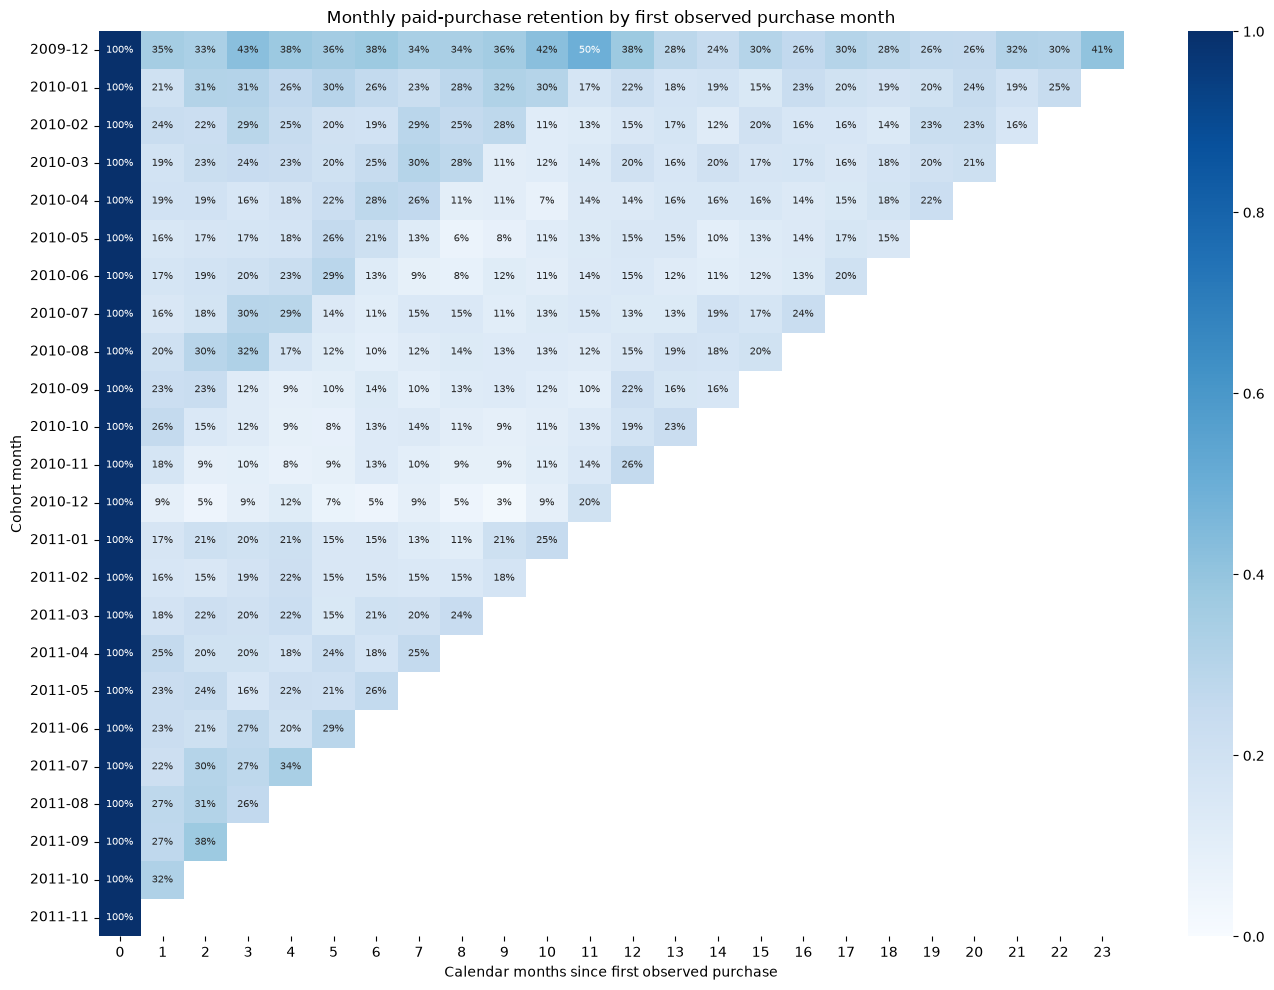

In [3]:
Path("../reports/figures").mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(14, 10))

sns.heatmap(
    retention,
    mask=retention.isna(),
    annot=True,
    fmt=".0%",
    cmap="Blues",
    vmin=0,
    vmax=1,
    annot_kws={"fontsize": 7}
)

plt.title("Monthly paid-purchase retention by first observed purchase month")
plt.xlabel("Calendar months since first observed purchase")
plt.ylabel("Cohort month")
plt.tight_layout()

plt.savefig(
    "../reports/figures/monthly_cohort_retention.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

retention.to_csv("../data/processed/monthly_cohort_retention.csv")
cohort_sizes.rename("customers").to_csv(
    "../data/processed/monthly_cohort_sizes.csv"
)

In [4]:
comparison_counts = cohort_counts.loc[
    cohort_counts.index > pd.Period("2009-12", freq="M")
].copy()

comparison_sizes = cohort_sizes.reindex(comparison_counts.index)

rows = []

for month in [1, 3, 6, 12]:
    # Include only cohorts with a fully observed follow-up month.
    eligible = comparison_counts[month].notna()

    customers_in_cohorts = comparison_sizes.loc[eligible].sum()
    returning_customers = comparison_counts.loc[eligible, month].sum()

    rows.append({
        "months_after_first_purchase": month,
        "eligible_cohorts": int(eligible.sum()),
        "customers_in_eligible_cohorts": int(customers_in_cohorts),
        "returning_customers": int(returning_customers),
        "repeat_purchase_pct": (
            returning_customers / customers_in_cohorts * 100
            if customers_in_cohorts > 0 else float("nan")
        ),
    })

retention_summary = pd.DataFrame(rows)

retention_summary.round(2)

,months_after_first_purchase,eligible_cohorts,customers_in_eligible_cohorts,returning_customers,repeat_purchase_pct
0,1,22,4704,990,21.05
1,3,20,4294,899,20.94
2,6,17,3978,729,18.33
3,12,11,3311,609,18.39


In [5]:
retention_summary.to_csv(
    "../data/processed/retention_summary.csv",
    index=False
)

## Key findings and limitations

- Month-1 paid repeat-purchase rate: 21.05% (990 / 4,704).
- Month-3 paid repeat-purchase rate: 20.94% (899 / 4,294).
- Month-6 paid repeat-purchase rate: 18.33% (729 / 3,978).
- Month-12 paid repeat-purchase rate: 18.39% (609 / 3,311).

### Interpretation

Each rate measures purchasing in one specific calendar month after
the first observed purchase month. It does not measure whether
a customer returned at any time within the whole follow-up period.

### Limitations

- Different follow-up months use different eligible cohorts.
- First observed purchase is not necessarily true customer acquisition.
- The December 2009 boundary cohort is excluded from these headline rates.
- The incomplete December 2011 period is excluded.
- Customers without IDs and non-paid purchase lines are excluded.
- Inactivity in a particular month does not establish permanent churn.